<a href="https://colab.research.google.com/github/6dsfg56sfg5/ML/blob/stuts/S3_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd

In [ ]:
data = pd.read_csv("NMES1988.csv")

In [ ]:
data['visits'].describe()

,visits
count,4406.000000
mean,5.774399
std,6.759225
min,0.000000
25%,1.000000
50%,4.000000
75%,8.000000
max,89.000000


In [ ]:
from scipy.stats import kurtosis, skew
kurtosis_value = kurtosis(data['visits'])
skewness_value = skew(data['visits'])
print("Эксцесс:", kurtosis_value)
print("Асимметрия:", skewness_value)

Эксцесс: 20.2064540726094
Асимметрия: 3.3381744056944953


In [ ]:
from scipy.stats import shapiro
stat, p_value = shapiro(data['visits'])
print("p-value:", p_value)

p-value: 5.712918721726831e-65


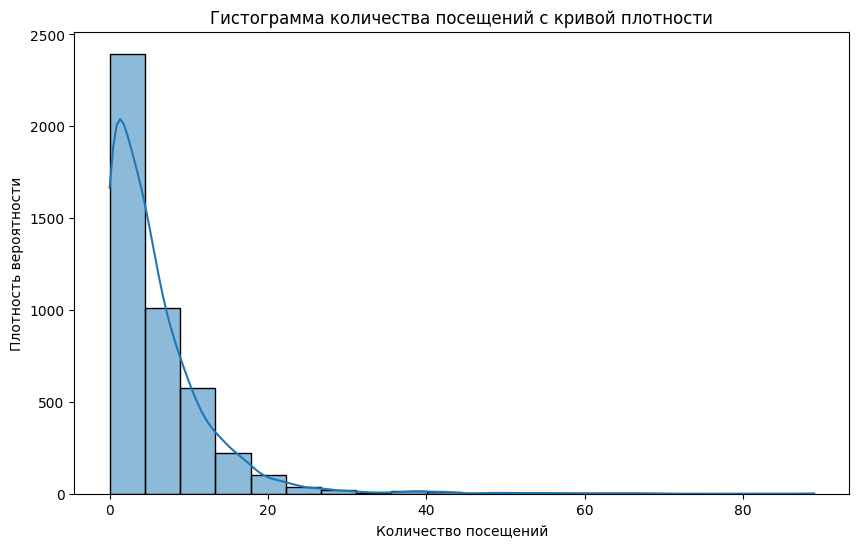

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(10, 6))
sns.histplot(data['visits'], kde=True, bins=20)
plt.xlabel("Количество посещений")
plt.ylabel("Плотность вероятности")
plt.title("Гистограмма количества посещений с кривой плотности")
plt.show()

In [ ]:
data.groupby('gender')['gender'].count()

,gender
gender,
female,2628
male,1778


In [ ]:
a=data['visits'].sum()
b=data['visits'].count()
c=int(a)/int(b)
c

5.774398547435315

In [ ]:
sd=0
bee=0
bee2=0
sumbee=0
for i in data['visits']:
  bee = i - c
  bee2= bee**2
  sumbee = sumbee +bee2
print((sumbee/(b-1))**0.5)
sd=(sumbee/(b-1))**0.5



6.759224615447886


In [ ]:
import numpy as np
np.std(data['visits'])

6.758457524187918

стандартное отклонение подсчитанно верно

In [ ]:
SE=sd/(b**0.5)
float(SE)

0.10182973939055254

In [ ]:
float(data['visits'].sem())

0.10182973939055254

Excellent!

In [ ]:
np.quantile(data['visits'], [0.25, 0.5, 0.75])

array([1., 4., 8.])

In [ ]:
data['visits'].describe()

,visits
count,4406.000000
mean,5.774399
std,6.759225
min,0.000000
25%,1.000000
50%,4.000000
75%,8.000000
max,89.000000


normal


In [ ]:
print(data.groupby('gender')['visits'].describe())

         count      mean       std  min  25%  50%  75%   max
gender                                                      
female  2628.0  6.014079  6.589852  0.0  2.0  4.0  8.0  61.0
male    1778.0  5.420135  6.988903  0.0  1.0  4.0  7.0  89.0


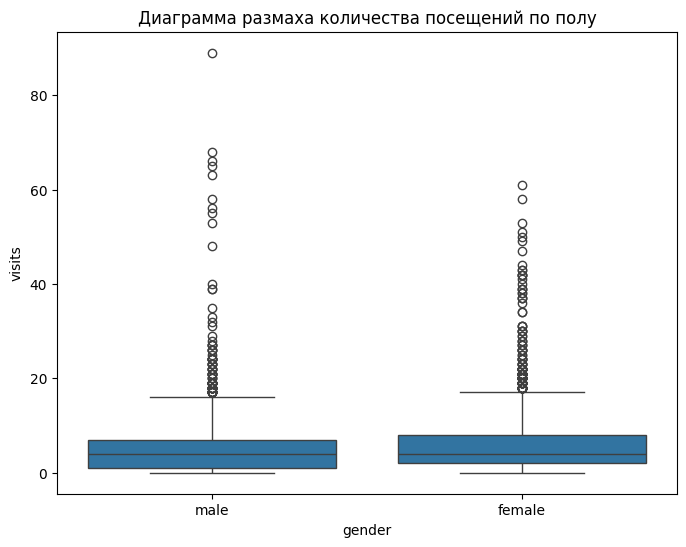

In [ ]:
plt.figure(figsize=(8, 6))
sns.boxplot(x='gender', y='visits', data=data)
plt.title("Диаграмма размаха количества посещений по полу")
plt.show()

In [ ]:
median_by_gender_age = data.groupby(['gender', 'married'])['visits'].median()
print(median_by_gender_age)

gender  married
female  no         4.0
        yes        4.0
male    no         2.0
        yes        4.0
Name: visits, dtype: float64


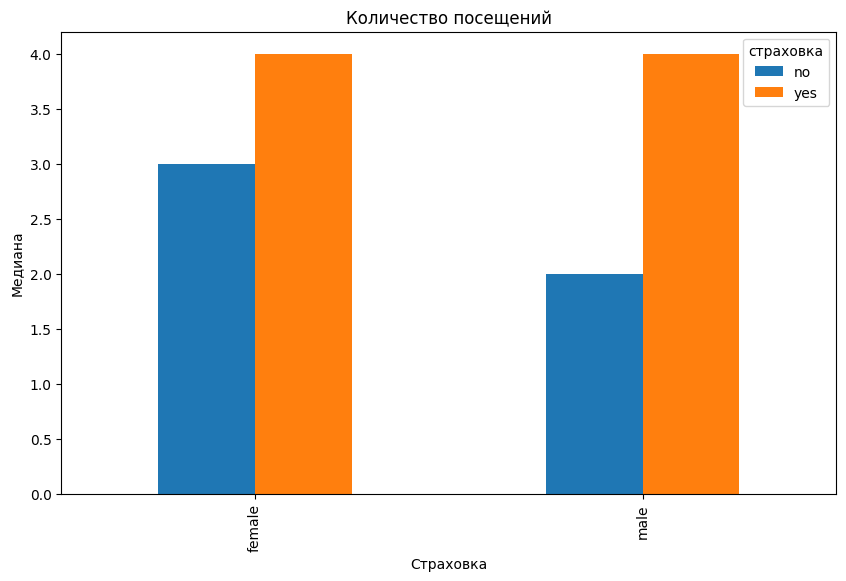

In [ ]:
medians = data.groupby(['gender', 'insurance'])['visits'].median().unstack()
medians.plot(kind='bar', figsize=(10, 6))
plt.xlabel("Страховка")
plt.ylabel("Медиана")
plt.title("Количество посещений")
plt.legend(title="страховка")
plt.show()

In [ ]:
from scipy import stats
def confidence_interval(data, confidence=0.95):
    n = len(data)
    mean = np.mean(data)
    sem = stats.sem(data)
    h = sem * stats.t.ppf((1 + confidence) / 2, n - 1)
    return mean, mean - h, mean + h
mean_visits, ci_lower, ci_upper = confidence_interval(data['visits'].dropna())
print(f"Среднее: {mean_visits:.2f}")
print(f"95% доверительный интервал: [{ci_lower:.2f}, {ci_upper:.2f}]")


Среднее: 5.77
95% доверительный интервал: [5.57, 5.97]


Text(0, 0.5, 'Количество посещений')

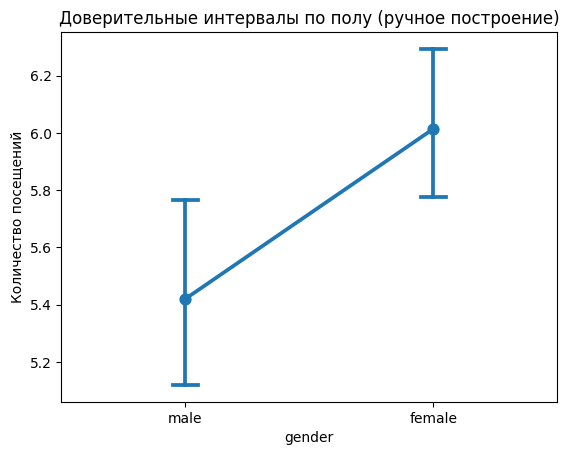

In [ ]:
sns.pointplot(x='gender', y='visits', data=data, capsize=0.1)
plt.title('Доверительные интервалы по полу (seaborn)')
plt.ylabel('Количество посещений')
plt.title('Доверительные интервалы по полу (ручное построение)')
plt.ylabel('Количество посещений')


In [ ]:
data.groupby('married')['age'].median()

,age
married,
no,7.5
yes,7.2


In [ ]:
data.groupby(['married','gender'])['age'].median()

married  gender
no       female    7.5
         male      7.4
yes      female    7.1
         male      7.2
Name: age, dtype: float64

Text(0, 0.5, 'age')

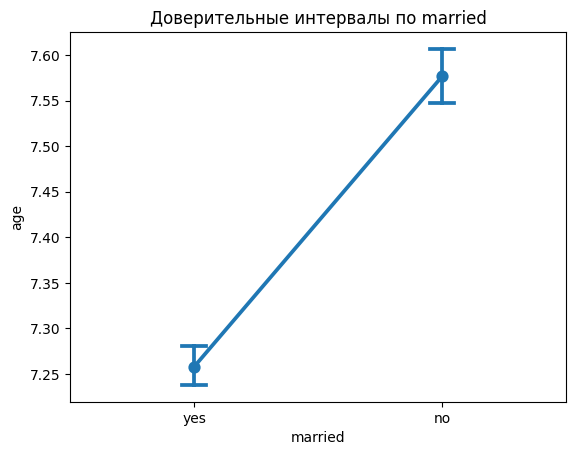

In [ ]:
sns.pointplot(x='married', y='age', data=data, capsize=0.1)
plt.title('Доверительные интервалы по married')
plt.ylabel('age')

доверительный интервал у группы no merried больше чем у их аппонентов на 3 года. Можно с уверенностью заявить, что холостые респонденты живут дольше чем женатые


<Axes: xlabel='married', ylabel='age'>

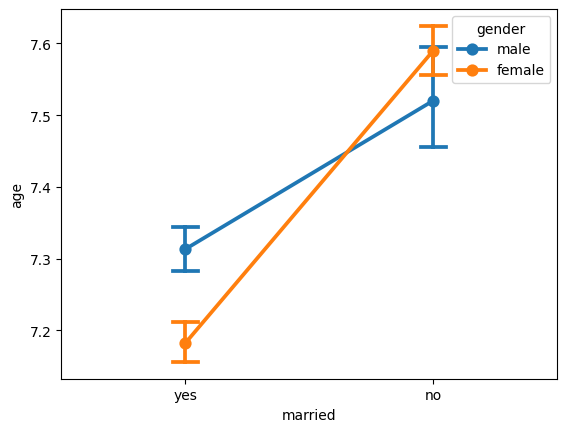

In [ ]:
sns.pointplot(x='married', y='age', hue ='gender', data=data, capsize=0.1)

Печальная теория подтвердилась даже при сегрегации по половому признаку.

Также приходт на ум единичная гипотеза о том, что female живут дольше male

<Axes: xlabel='gender', ylabel='age'>

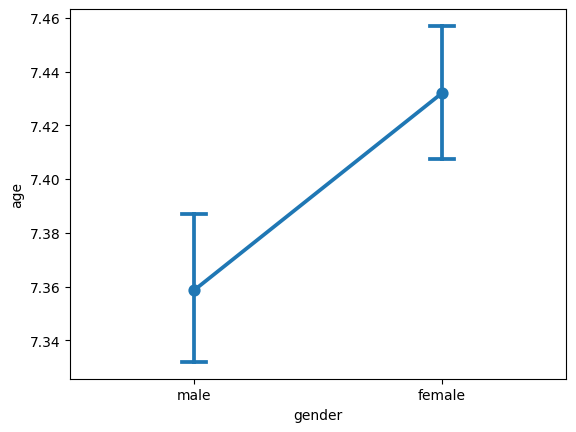

In [ ]:
sns.pointplot(x='gender', y ='age', data=data, capsize=0.1)

На данных из текущего банка знаний единичная гипотеза подтвердилась